In [ ]:
NOMBRE = "Fabricio Cárdenas Araiza"
MATRICULA = "82265"
DATASET_ASIGNADO = "homicidios"

print(f"Alumno: {NOMBRE}")
print(f"Matrícula: {MATRICULA}")
print(f"Dataset asignado: {DATASET_ASIGNADO}")

Alumno: Fabricio Cárdenas 
Matrícula: 82265
Dataset asignado: homicidios


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

# --- NO MODIFICAR: configuración de los 5 datasets del examen ---
DATASETS = {
    "alcohol": {
        "csv": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/share-of-adults-who-drank-alcohol-in-last-year.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "alcohol__consumers_past_12_months__pct__age_standardized__sex_both_sexes",
        "filtro_paises": "code",       # columna a usar para filtrar países reales vs. agregados
        "descripcion": "Porcentaje de adultos (15+) que bebieron alcohol en el ultimo anio",
        "unidad": "%",
    },
    "migracion": {
        "csv": "https://ourworldindata.org/grapher/migrant-populations.csv?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "meta": "https://ourworldindata.org/grapher/migrant-populations.metadata.json?v=1&csvType=full&useColumnShortNames=true&metric=immigrants&unit=number",
        "valor_col": "immigrants_all",
        "filtro_paises": "owid_region",
        "descripcion": "Numero total de inmigrantes internacionales residiendo en el pais",
        "unidad": "personas",
    },
    "desnutricion": {
        "csv": "https://ourworldindata.org/grapher/number-undernourished.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/number-undernourished.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "_2_1_1_number_of_undernourished_people__000000000024001__value__006132__millions",
        "filtro_paises": "code",
        "descripcion": "Numero de personas subalimentadas (desnutricion)",
        "unidad": "personas",
    },
    "pib": {
        "csv": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/gdp-per-capita-worldbank-constant-usd.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "ny_gdp_pcap_kd",
        "filtro_paises": "code",
        "descripcion": "PIB per capita (dolares constantes de 2015)",
        "unidad": "USD",
    },
    "homicidios": {
        "csv": "https://ourworldindata.org/grapher/homicides-unodc.csv?v=1&csvType=full&useColumnShortNames=true",
        "meta": "https://ourworldindata.org/grapher/homicides-unodc.metadata.json?v=1&csvType=full&useColumnShortNames=true",
        "valor_col": "value__category_total__sex_total__age_total__unit_of_measurement_counts",
        "filtro_paises": "owid_region",
        "descripcion": "Numero de homicidios intencionales por anio",
        "unidad": "homicidios",
    },
}

assert DATASET_ASIGNADO in DATASETS, (
    "DATASET_ASIGNADO debe ser uno de: " + ", ".join(DATASETS.keys())
)

config = DATASETS[DATASET_ASIGNADO]
print(f"Cargando dataset: {DATASET_ASIGNADO}")
print(f"Descripcion: {config['descripcion']} ({config['unidad']})")


Cargando dataset: homicidios
Descripcion: Numero de homicidios intencionales por anio (homicidios)


In [9]:
# Carga de datos y metadatos desde Our World in Data
df = pd.read_csv(
    config["csv"],
    storage_options={'User-Agent': 'Our World In Data data fetch/1.0'}
)
metadata = requests.get(config["meta"]).json()

# Renombramos la columna de valor a "valor" para trabajar mas comodo durante todo el notebook
df = df.rename(columns={config["valor_col"]: "valor"})


In [8]:
df.head(25)

,entity,code,year,valor,owid_region
0,Afghanistan,AFG,2009,1115.000,Asia
1,Afghanistan,AFG,2010,983.000,Asia
2,Afghanistan,AFG,2011,1231.000,Asia
3,Afghanistan,AFG,2012,1948.000,Asia
4,Afghanistan,AFG,2015,3367.000,Asia
5,Afghanistan,AFG,2016,2318.000,Asia
6,Afghanistan,AFG,2017,2424.000,Asia
7,Afghanistan,AFG,2018,2474.000,Asia
8,Afghanistan,AFG,2019,2712.000,Asia
9,Afghanistan,AFG,2020,2570.000,Asia


In [10]:
# Forma del dataset (filas, columnas)
df.shape


(4914, 5)

In [11]:
# Tipos de datos e informacion general
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4914 entries, 0 to 4913
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   entity       4914 non-null   str    
 1   code         4399 non-null   str    
 2   year         4914 non-null   int64  
 3   valor        4914 non-null   float64
 4   owid_region  4220 non-null   str    
dtypes: float64(1), int64(1), str(3)
memory usage: 192.1 KB


In [12]:
# Estadisticas descriptivas de la columna 'valor'
df['valor'].describe()


count      4914.000000
mean       8582.853861
std       37590.820449
min           0.000000
25%          37.000000
50%         256.500000
75%        1171.968475
max      450728.880000
Name: valor, dtype: float64

In [13]:
# Conteo de valores nulos por columna
df.isnull().sum()


entity           0
code           515
year             0
valor            0
owid_region    694
dtype: int64

**Interpretación (2-3 líneas):** ¿qué observas sobre los valores nulos, el rango de
años y el tipo de variable con la que vas a trabajar?

Tanto entity, year y valor estan completados, pero sus valores nulos estan principalmente en code y owid_region, esto es debido a que entidades como "Africa" no son paises individuales si no como conjunto de paises de un continente. El variable a usar sera puro float64 e int64

## 4. Preguntas de análisis

A continuación responde las 10 preguntas. 

Cada una tiene una celda de código para su solución y, cuando aplica, 
una celda de texto para tu interpretación. Recuerda que tu
dataset (`DATASET_ASIGNADO`) puede o no tener la columna `owid_region`; revisa el
diccionario `DATASETS` de la celda de configuración para saber qué columna (`code` u
`owid_region`) te toca usar para distinguir países reales de agregados (continentes,
"World", grupos de ingreso, etc.).

### Pregunta 1 — Filtrado de países reales y ranking

Filtra el DataFrame para quedarte solo con países reales (usa la columna indicada en `config['filtro_paises']` de tu dataset). Guarda el resultado en una nueva variable `df_paises`. ¿Cuántos países distintos hay? Muestra los 10 países con mayor valor y los 10 con menor valor.

In [25]:
# Solo paises
df_paises = df[df[config["filtro_paises"]].notnull()].copy()

cantidad_paises = df_paises["entity"].nunique()
print("Cantidad de países distintos:", cantidad_paises)

# ordenamiento de mayor a menor y sacar los 10 primeros
df_descendente = df_paises.sort_values("valor", ascending=False).drop_duplicates(subset=["entity"])
primeros_10_mayor = df_descendente.head(10)
print("\n--- Top 10 con mayor valor ---")
display(primeros_10_mayor.loc[:, ["entity", "year", "valor"]])

# Al reves
df_ascendente = df_paises.sort_values("valor", ascending=True).drop_duplicates(subset=["entity"])
primeros_10_menor = df_ascendente.head(10)
print("\n--- Top 10 con menor valor ---")
display(primeros_10_menor.loc[:, ["entity", "year", "valor"]])

Cantidad de países distintos: 200

--- Top 10 con mayor valor ---


,entity,year,valor
716,Brazil,2017,63788.0
3093,Nigeria,2016,63400.0
2009,India,1992,49688.0
3657,Russia,1994,47870.0
2748,Mexico,2020,36773.0
972,Colombia,1993,28441.0
947,China,1995,27356.0
4078,South Africa,2022,27272.0
4639,United States,1991,24703.0
4780,Venezuela,2014,19030.0



--- Top 10 con menor valor ---


,entity,year,valor
4747,Vatican,2011,0.0
150,Anguilla,1994,0.0
1991,Iceland,2008,0.0
3832,San Marino,2008,0.0
468,Bahrain,2020,0.0
138,Andorra,2013,0.0
3699,Saint Helena,1994,0.0
4516,Turks and Caicos Islands,1991,0.0
2874,Montserrat,2017,0.0
724,British Virgin Islands,1991,0.0


**Interpretación:**

Brasil, India o Estados unidos tienen mas homicidios que Mexico, Mientras que los menos homicidios como el Vaticano o Andorra tienen muy buena seguridad

### Pregunta 2 — Filtro por país y rango de años

Elige dos paises (Mexico y algún otro de tu interés) y filtra `df_paises` para mostrar únicamente su información dentro del rango de años disponible para ambos.

In [27]:
# Variables de los 2 paises
datos_mexico = df_paises[(df_paises["entity"] == "Mexico")]
datos_japon = df_paises[(df_paises["entity"] == "Japan")]

# Convertirlos a numpy
anios_mexico = datos_mexico["year"].to_numpy()
anios_japon = datos_japon["year"].to_numpy()

# Realizar join
anios_en_comun = np.intersect1d(anios_mexico, anios_japon)

# Y clasifica por años
df_filtrado_p2 = df_paises[(df_paises["entity"].isin(["Mexico", "Japan"])) & (df_paises["year"].isin(anios_en_comun))]
df_filtrado_p2["entity"].value_counts()

entity
Japan     34
Mexico    34
Name: count, dtype: int64

### Pregunta 3 — Comparación entre países

Elige 5 países de tu interés (de distintos continentes) y compara el valor de tu indicador en el año más reciente disponible. ¿Cuál tiene el valor más alto y cuál el más bajo? Calcula la diferencia entre ambos.

In [28]:
anio_objetivo = 2021
df_anio = df_paises[df_paises['year'] == anio_objetivo].copy()

# 5 paises
paises_seleccionados = df_anio[(df_anio["entity"].isin(["Mexico", "Japan", "Germany", "South Africa", "Australia"]))]

# Calcular vectores
valor_maximo = paises_seleccionados["valor"].max()
valor_minimo = paises_seleccionados["valor"].min()

entidad_maxima = paises_seleccionados.loc[paises_seleccionados["valor"].idxmax()]["entity"]
entidad_minima = paises_seleccionados.loc[paises_seleccionados["valor"].idxmin()]["entity"]

print(f"País con valor más alto: {valor_maximo} ({entidad_maxima})")
print(f"País con valor más bajo: {valor_minimo} ({entidad_minima})")
print(f"Diferencia: {valor_maximo - valor_minimo}")

País con valor más alto: 35700.0 (Mexico)
País con valor más bajo: 193.0 (Australia)
Diferencia: 35507.0


**Interpretación:**

Mas que evidente que Mexico tiene muy altos homicidios a diferencia de Japon, demostrando la desigualdad y la corrupcion

### Pregunta 4 — Comparación entre grupos

Define dos grupos de países, el primero "latinoamerica" con Mexico, Colombia y Argentina, y el segundo "Asia" con China, Japon y Vietnam ( si algun pais no tiene informacion disponible, sustitúyelo por algún otro) y calcula el promedio de tu indicador en el año más reciente disponible.

In [29]:
# Se usa el dataframe anterior
latinoamerica = df_anio[(df_anio["entity"].isin(["Mexico", "Colombia", "Argentina"]))]
asia = df_anio[(df_anio["entity"].isin(["China", "Japan", "Vietnam"]))]

media_latinoamerica = latinoamerica["valor"].mean()
media_asia = asia["valor"].mean()

print(f"Promedio Latinoamérica ({anio_objetivo}): {media_latinoamerica:.2f}")
print(f"Promedio Asia ({anio_objetivo}): {media_asia:.2f}")

Promedio Latinoamérica (2021): 16962.67
Promedio Asia (2021): 285.00


**Interpretación:**

E igualmente que la alterior, latinoamerica tiene muchos mas homicidios de Asia en general, reflejandonos nuestras culturas, politicas y como vivimos en la sociedad

### Pregunta 5 — Tendencia temporal de un país

Para un país de tu elección, analiza cómo cambió tu indicador a lo largo del tiempo disponible en el dataset. ¿En qué año tuvo su valor máximo y en cuál el mínimo? ¿La tendencia general es creciente, decreciente o fluctuante?

In [32]:
# Filtrar a México y sacar picos
datos_mexico = df_paises[(df_paises["entity"] == "Mexico")]

minimo_historico = datos_mexico["valor"].min()
maximo_historico = datos_mexico["valor"].max()

anio_del_minimo = datos_mexico.loc[datos_mexico["valor"].idxmin()]["year"]
anio_del_maximo = datos_mexico.loc[datos_mexico["valor"].idxmax()]["year"]

print(f"Valor Máximo: {maximo_historico} (Año {anio_del_maximo})")
print(f"Valor Mínimo: {minimo_historico} (Año {anio_del_minimo})")

Valor Máximo: 36773.0 (Año 2020)
Valor Mínimo: 8867.0 (Año 2007)


**Interpretación:**

Elegi Mexico porque tuvimos una especie de "epoca dorada" durante los 2000s, pero en los ultimos años se han reflejado la necesidad de trabajar como sicarios debido a la falta de oportunidades en muchos lados de Mexico

### Pregunta 6 — Cambio porcentual

Para Mexico, calcula el cambio porcentual entre el primer y el último año con datos disponible. ¿presenta un incremento relativo o una caída? En tus palabras, ¿a qué crees que se debe el resultado? 

In [33]:
# Se ordenan los datos y extraer con iloc
mexico_ordenado = df_paises[(df_paises["entity"] == "Mexico")].sort_values("year")

primer_registro = mexico_ordenado.iloc[0]
ultimo_registro = mexico_ordenado.iloc[-1]

valor_inicial = primer_registro["valor"]
valor_final = ultimo_registro["valor"]

cambio_porcentual = ((valor_final - valor_inicial) / valor_inicial) * 100
print(f"Cambio porcentual de {primer_registro['year']} a {ultimo_registro['year']}: {cambio_porcentual:.2f}%")

Cambio porcentual de 1990 a 2023: 122.54%


Se esperaba un enorme aumento en el porcentaje considerando el enorme aumento del crecimiento del pais con los embarazos no planeados

### Pregunta 7 — Estadísticas descriptivas con NumPy

Usando NumPy (no `.describe()` de pandas), calcula la media, la mediana y la desviación estándar de tu columna valor entre todos los países reales, para el año más reciente disponible. 
Recuerda filtrar los `NaN` antes de calcular.

In [36]:
# Pasar a NumPy
anio_objetivo = 2021
df_anio = df_paises[df_paises['year'] == anio_objetivo].copy()

valores_numpy = df_anio["valor"].dropna().to_numpy()

media_numpy = np.mean(valores_numpy)
mediana_numpy = np.median(valores_numpy)
desviacion_estandar_numpy = np.std(valores_numpy)

print(f"--- Medidas Estadísticas Descriptivas con NumPy ({anio_objetivo}) ---")
print(f"Media: {media_numpy:.2f}")
print(f"Mediana: {mediana_numpy:.2f}")
print(f"Desviación estándar: {desviacion_estandar_numpy:.2f}")


--- Medidas Estadísticas Descriptivas con NumPy (2021) ---
Media: 2321.58
Mediana: 126.00
Desviación estándar: 7206.21


**Interpretación:**

Alta dispersion de datos respecto a la media, tambien contando que la media es mas mayor que la mediana. Todo debido al pequeño grupo de paises que tienen enormes homicidios

### Pregunta 8 — Visualización de tendencia

Crea una gráfica de líneas con matplotlib que muestre la evolución de tu indicador a lo largo del tiempo para 3 países de tu elección, en una sola figura, con título, etiquetas de ejes y leyenda.

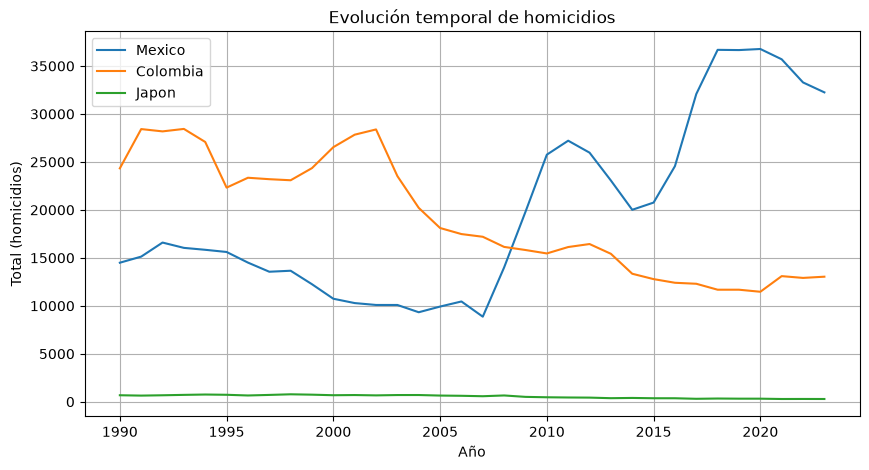

In [37]:
# Variables por país y trazado
datos_mexico = df_paises[(df_paises["entity"] == "Mexico")]
datos_colombia = df_paises[(df_paises["entity"] == "Colombia")]
datos_japon = df_paises[(df_paises["entity"] == "Japan")]

anios_mexico = datos_mexico["year"].to_numpy()
valores_mexico = datos_mexico["valor"].to_numpy()

anios_colombia = datos_colombia["year"].to_numpy()
valores_colombia = datos_colombia["valor"].to_numpy()

anios_japon = datos_japon["year"].to_numpy()
valores_japon = datos_japon["valor"].to_numpy()

plt.figure(figsize=(10, 5))
plt.plot(anios_mexico, valores_mexico, label="Mexico")
plt.plot(anios_colombia, valores_colombia, label="Colombia")
plt.plot(anios_japon, valores_japon, label="Japon")

plt.title("Evolución temporal de homicidios")
plt.xlabel("Año")
plt.ylabel(f"Total ({config['unidad']})")
plt.grid(True)
plt.legend()
plt.show()

**Interpretación:**

Habian mas homicidios en colombia debido a Pablo Escobar y su reinado, ahora que se controlo la seguridad, Mexico los rebaso por los reinados del Chapo y el Mencho

### Pregunta 9 — Visualización integradora

Crea dos gráficas de barras (horizontales o verticales) con el Top 10 de países según tu indicador en la primera consulta el año de tu nacimiento, y en la segunda el año 2023, ordenados de mayor a menor.  Qué movimientos hubo en ambas gráficas?
Agrega título y etiquetas de ejes.

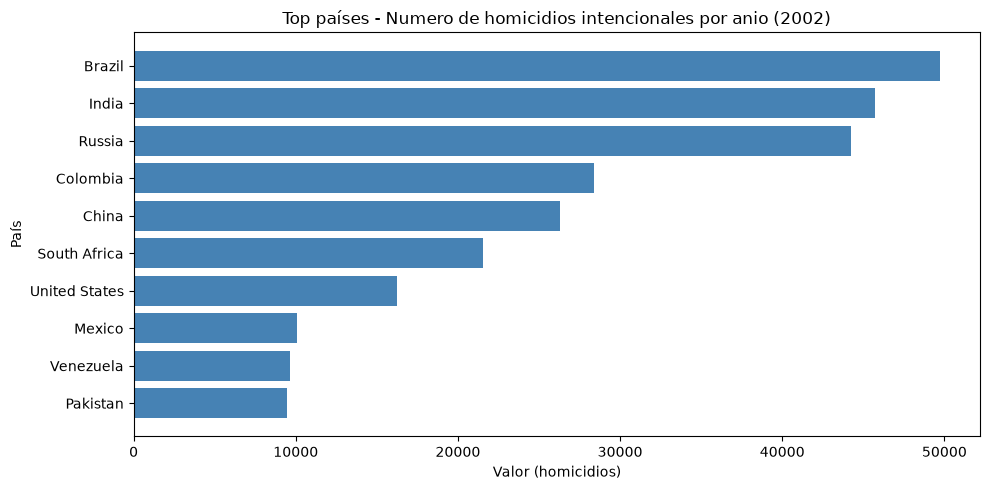

In [38]:
# Pregunta 9
# Tu codigo aqui
df_paises = df[df[config["filtro_paises"]].notnull()]

anio_consultado = 2002

top = (
    df_paises[df_paises['year'] == anio_consultado]
    .sort_values('valor', ascending=False)
    .head(10)
)
# Grafica de barras horizontales
plt.figure(figsize=(10, 5))
plt.barh(top['entity'], top['valor'], color='steelblue')

plt.xlabel(f"Valor ({config['unidad']})")
plt.ylabel("País")
plt.title(f"Top países - {config['descripcion']} ({anio_consultado})")

plt.gca().invert_yaxis()  # para que el país con el valor mas alto quede arriba
plt.tight_layout()
plt.show()


**Interpretación:**

Los paises con mas gente son los que mantienen mas homicidios por su enorme volumen de poblacion, pero Mexico se disparo en la ultima decada por todas las crisis.

## 5. Conclusión general

En 5 - 10 líneas, resume qué aprendiste sobre el dataset que te tocó trabajar: ¿qué
patrones encontraste?, ¿qué limitaciones tiene la información (por ejemplo, valores
absolutos sin normalizar por población, datos faltantes, etc.)?, ¿qué harías distinto si
tuvieras más tiempo?

Durante este análisis, se evidenció un claro patrón de violencia en Latinoamérica. En el caso de México, la alta inseguridad y su escalada histórica son innegables, reflejando el impacto de malas decisiones políticas. Sin embargo, la mayor limitación de este dataset es el uso exclusivo de números absolutos, lo que genera un fuerte sesgo demográfico; los países masivos siempre encabezan las listas, impidiendo saber si son verdaderamente más peligrosos. Para solucionarlo, haría un merge con información poblacional para calcular el índice relativo de homicidios per cápita, obteniendo así comparaciones mucho más justas y exactas.

## 6. Entrega

1. Verifica que el notebook corra completo de arriba hacia abajo sin errores (`Kernel > Restart & Run All`).
2. Guarda el archivo con el nombre: `apellido_nombre_examen_parcial1.ipynb`.
3. Súbelo al repositorio de GitHub del curso, en una carpeta para este examen.
4. Comparte el link de tu repo y envia una copia del notebook por teams.
